In [1]:
import pandas as pd
import time
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

In [2]:
df = pd.read_csv("datasets/emails.csv")

print("Dataset Preview:")
print(df.head())
print("Dataset Shape:", df.shape)

Dataset Preview:
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]
Dataset Shape: (5172, 3002)


In [3]:
X = df.drop(columns=["Email No.", "Prediction"])
y = df["Prediction"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [5]:
print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (4137, 3000)
Testing Shape: (1035, 3000)


In [6]:
models = {
    "KNN": KNeighborsClassifier(
        n_neighbors=5, metric="cosine"
    ),
    "SVM": LinearSVC(random_state=42)
}

In [7]:
results = {}

for name, model in models.items():

    start = time.perf_counter()

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    elapsed = time.perf_counter() - start

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    }

    print(f"\n--- {name} Results ---")
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

    for metric, value in results[name].items():
        print(f"{metric}: {value:.4f}")

    print("Execution Time:", round(elapsed, 4), "seconds")



--- KNN Results ---
Confusion Matrix:
 [[662  73]
 [ 60 240]]
Accuracy: 0.8715
Precision: 0.7668
Recall: 0.8000
F1 Score: 0.7830
Execution Time: 0.4149 seconds

--- SVM Results ---
Confusion Matrix:
 [[723  12]
 [  9 291]]
Accuracy: 0.9797
Precision: 0.9604
Recall: 0.9700
F1 Score: 0.9652
Execution Time: 1.2098 seconds


C:\Raj Important installations\Minicomda\envs\Practical\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(



Model Comparison:
     Accuracy  Precision  Recall  F1 Score
KNN  0.871498   0.766773    0.80  0.783034
SVM  0.979710   0.960396    0.97  0.965174


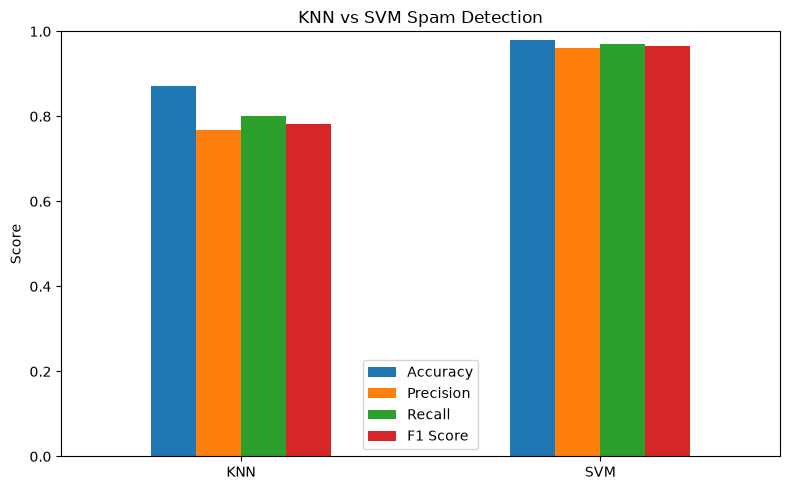

In [8]:
comparison = pd.DataFrame(results).T

print("\nModel Comparison:")
print(comparison)

comparison.plot(kind="bar", figsize=(8, 5), ylim=(0, 1))

plt.title("KNN vs SVM Spam Detection")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()